In [19]:
%matplotlib widget

In [20]:
%%capture
from ocelot import *
from ocelot.gui import *
import matplotlib.pyplot as plt
import numpy as np
from felarc.simple_tba import get_tba_dispersion_condition, get_quad_strengths, TBADefinition, make_tba, TripleBendAchromat
from felarc.plot import plot_optics, plot_r56_full
from felarc.t20 import ARC_ANGLE_RADo

The T20 arc comprises a $>6°$ bend.  We start with the simplest isochronous lattice: three identical dipoles, with a total bending angle equal to the 6° we are after.  We also choose a 3m dipole on the basis that in Nina's design we covered the $6°$ in 9m of dipole.

In [21]:
DIPOLE_ANGLE = ARC_ANGLE_RAD / 3
DIPOLE_LENGTH = 3
dx, dxp = get_tba_dispersion_condition(dipole_length=DIPOLE_LENGTH, dipole_angle=DIPOLE_ANGLE)

In [22]:
print(dx, dxp)

-0.0261740907458337 -0.01746038085732892


In [23]:
ad = TBADefinition(dipole_length=DIPOLE_LENGTH, dipole_angle=DIPOLE_ANGLE, l1=1., l2=1, l3=2., qlength=1., k11=1, k12=-1)
mlat = make_tba(ad)
k11, k12 = get_quad_strengths(ad)

Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 57
         Function evaluations: 107
[ 0.87458145 -1.33585445]


In [24]:
print(k11, k12)
ad.k11 = k11
ad.k12 = k12
print(ad)
tba = make_tba(ad)

0.8745814493342622 -1.3358544522347424
TBADefinition(dipole_length=3, dipole_angle=0.03490658503988659, l1=1.0, l2=1, l3=2.0, qlength=1.0, k11=np.float64(0.8745814493342622), k12=np.float64(-1.3358544522347424))


In [25]:
twiss0 = Twiss(beta_x=20, beta_y=100)
twisses = twiss(tba.mlat, twiss0)
dx_actual, dxp_actual = twisses[-1].Dx, twisses[-1].Dxp
print(f"Required Dx: {dx}, Actual Dx: {dxp}")
print(f"Fitted Dx: {dx_actual}, Actual Dx: {dxp_actual}")

Required Dx: -0.0261740907458337, Actual Dx: -0.01746038085732892
Fitted Dx: 1.6299661210333882e-07, Actual Dx: 9.458781285998086e-08


(<Figure size 1280x480 with 5 Axes>,
 array([<Axes: >, <Axes: ylabel='$D_x$ / m'>,
        <Axes: ylabel='$\\rho^{-1}\\,/\\,\\mathrm{m}^{-1}$'>,
        <Axes: ylabel='$D\\rho^{-1}$'>,
        <Axes: xlabel='$s$ / m', ylabel='$R_{56}$ / mm'>], dtype=object))

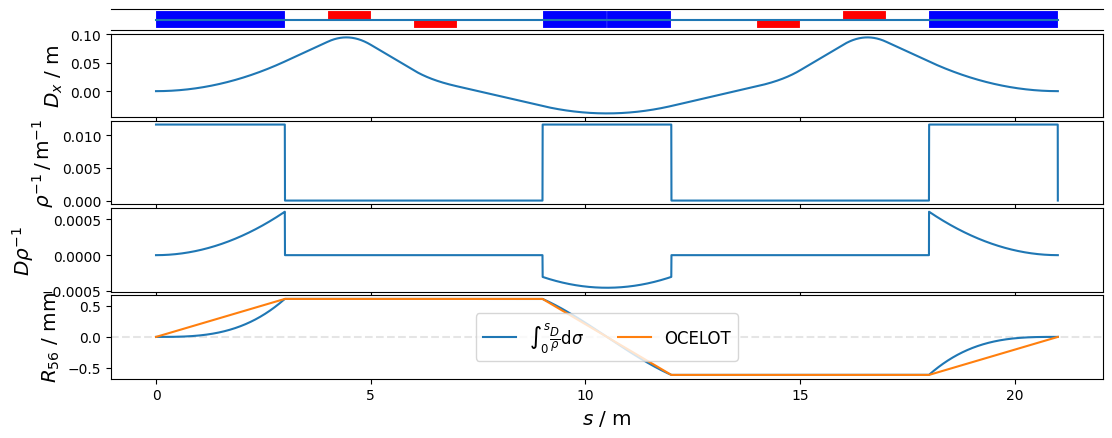

In [8]:
tba_full = make_tba(ad)
plot_r56_full(twiss0, tba_full.mlat)

Now checking the transverse beam optics, we see that although the dispersion has a waist in the middle dipole and that $R_{56}=0$ for the arc, the transverse beam optics diverge considerably:


(<Figure size 1280x480 with 4 Axes>,
 array([<Axes: >, <Axes: ylabel='$\\beta$ / m'>, <Axes: ylabel='$D$ / m'>,
        <Axes: xlabel='$s$ / m', ylabel="$D'$ / rad">], dtype=object))

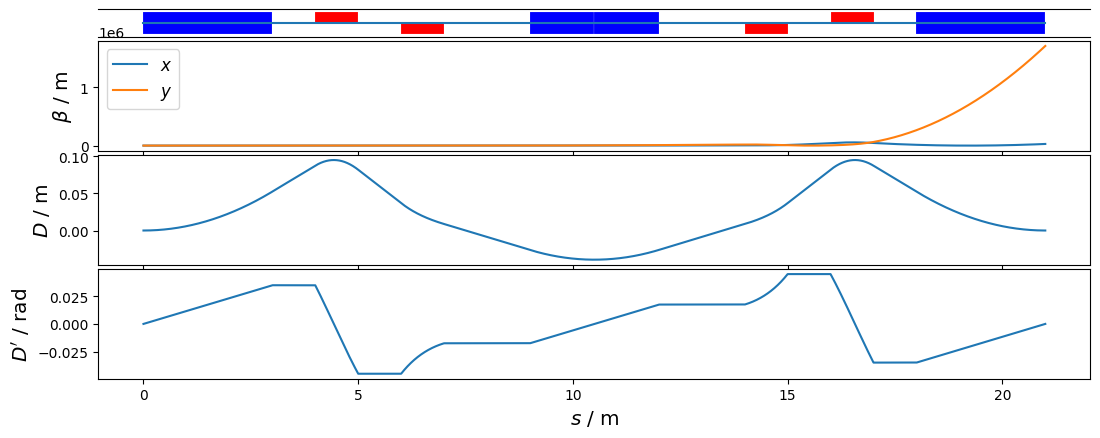

In [9]:
plot_optics(twiss0, tba_full.mlat)

So we need a beta function waist (i.e. $\alpha_x = \alpha_y = 0$) in the middle of the arc, too.  To do this, we match with some additional constraints.

In [18]:
from felarc.matching import match_twiss
from copy import deepcopy
def get_quad_strengths_new(tba: TripleBendAchromat, elements: list[Element]) -> None:
    # The book suggests varying a drift and a quad strength to match the two conditions
    # But here instead I'm going to use two quads to reach the condition.
    dx, dxp = get_tba_dispersion_condition(ad.dipole_length, ad.dipole_angle)
    twiss0 = Twiss(beta_x=30, beta_y=10, alpha_x=-0.5)
    result = match_twiss(
        tba.mlat,
        verbose=not True,
        max_iter=1_000_000,
        constr={
                # tba.markers.middle_dipole_start: {"Dx": dx, "Dxp": dxp},
                tba.markers.middle: {"alpha_x": 0.0, "alpha_y": 0.0}
               },
        vars=elements,
        tw=twiss0,
        method="simplex"
    )
vars = get_quad_strengths_new(tba, tba.components.all_elements)


Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 98
         Function evaluations: 183
Quadrupole(l=1.00000, k1=7.569959e-01, eid="ID_95797300_")
[ 7.56995920e-01 -1.16572279e+00  1.37977888e+00  5.83993089e-03
  5.45778690e-10]
